# Milestone 1: Understanding the TIHM Dataset (analysis notebook)

**Team members:** Aastha Mishra and Mia Martinez  
**Course:** CSCI 6380, Data Mining

This notebook holds the code and outputs for our exploration of the TIHM dataset (Palermo et al., *Scientific Data*, 2023). Each result has a short note under it. The longer discussion, the paper summary and the limitations are in the written report.

**What we analyzed:** the full dataset (all five CSV files, nothing was subsampled). We did not train any models.

**To run it:** get the five CSV files from Zenodo (https://doi.org/10.5281/zenodo.7622128), put them in a folder called `Dataset/` next to this notebook (or set the `TIHM_DATA_DIR` environment variable), then run all cells. See `README_milestone1.md`.

## Setup

In [1]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def find_data_dir():
    # look for the CSVs in a few likely places
    roots = (Path.cwd(), *Path.cwd().parents)
    cands = [os.environ.get("TIHM_DATA_DIR")]
    cands.extend(
        str(path)
        for root in roots
        for path in (
            root / "Dataset",
            root / "data",
            root / "analysisFiles" / "Dataset",
            root / "TIHM-Dataset" / "analysisFiles" / "Dataset",
        )
    )
    for c in cands:
        if c and (Path(c) / "Activity.csv").is_file():
            return Path(c).resolve()
    raise FileNotFoundError("Could not find Activity.csv. Set TIHM_DATA_DIR or put the CSVs in a Dataset folder.")

DATA_DIR = find_data_dir()
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

A = pd.read_csv(DATA_DIR / "Activity.csv",   parse_dates=["date"])
D = pd.read_csv(DATA_DIR / "Demographics.csv")
L = pd.read_csv(DATA_DIR / "Labels.csv",     parse_dates=["date"])
P = pd.read_csv(DATA_DIR / "Physiology.csv", parse_dates=["date"])
S = pd.read_csv(DATA_DIR / "Sleep.csv",      parse_dates=["date"])

# a plain calendar-day column makes it easy to count things per day
for df in (A, L, P, S):
    df["day"] = df["date"].dt.normalize()

print("Data loaded from:", DATA_DIR)

Data loaded from: /Users/aasthamishra/UGA/CS Classes/Fall 2026/CSCI6380 - Data Mining/sem_analysis/TIHM-Dataset/analysisFiles/Dataset


## 1. What is in the files?

In [2]:
tables = {"Activity": A, "Sleep": S, "Physiology": P, "Labels": L, "Demographics": D}
rows = []
for name, df in tables.items():
    base = df.drop(columns=["day"], errors="ignore")
    rows.append({
        "table": name,
        "rows": len(base),
        "columns": ", ".join(base.columns),
        "patients": base.patient_id.nunique(),
        "first date": base["date"].min().date() if "date" in base else "-",
        "last date": base["date"].max().date() if "date" in base else "-",
        "missing cells": int(base.isna().sum().sum()),
        "duplicate rows": int(base.duplicated().sum()),
    })
pd.DataFrame(rows).set_index("table")

,rows,columns,patients,first date,last date,missing cells,duplicate rows
table,,,,,,,
Activity,1030559,"patient_id, location_name, date",56,2019-04-01,2019-06-30,0,0
Sleep,461423,"patient_id, date, state, heart_rate, respirato...",17,2019-04-01,2019-06-30,0,0
Physiology,17679,"patient_id, date, device_type, value, unit",55,2019-04-01,2019-06-30,0,0
Labels,608,"patient_id, date, type",49,2019-04-04,2019-06-30,0,0
Demographics,56,"patient_id, age, sex",56,-,-,0,0


*Note:* No missing cells and no duplicate rows in any table. The patient counts are the more important column: Activity covers all 56 participants but Sleep covers only 17 and Labels only 49.

In [3]:
# a few raw rows from each table
for name in ["Activity", "Sleep", "Physiology", "Labels", "Demographics"]:
    print("---", name, "---")
    display(tables[name].drop(columns=["day"], errors="ignore").head(3))

# one busy day for one participant, event by event
pid = "c55f8"
busy_day = A[A.patient_id == pid].groupby("day").size().idxmax()
one_day = A[(A.patient_id == pid) & (A.day == busy_day)].sort_values("date")
print(f"\nParticipant {pid} on {busy_day.date()}: {len(one_day)} events. First 10:")
display(one_day[["date", "location_name"]].head(10))

--- Activity ---


,patient_id,location_name,date
0,0697d,Fridge Door,2019-06-28 13:03:29
1,0697d,Kitchen,2019-06-28 13:11:44
2,0697d,Front Door,2019-06-28 13:13:50


--- Sleep ---


,patient_id,date,state,heart_rate,respiratory_rate,snoring
0,0f352,2019-06-25 22:53:00,AWAKE,69.0,14.0,False
1,0f352,2019-06-25 22:54:00,AWAKE,66.0,14.0,False
2,0f352,2019-06-25 22:55:00,AWAKE,70.0,14.0,False


--- Physiology ---


,patient_id,date,device_type,value,unit
0,0697d,2019-06-28 13:42:09,Body Temperature,36.072,Cel
1,0697d,2019-06-28 13:42:44,Body Temperature,35.831,Cel
2,0697d,2019-06-28 13:43:40,Body Temperature,35.831,Cel


... (2 outputs left out)

--- Demographics ---


,patient_id,age,sex
0,b9d58,"(70, 80]",Female
1,c55f8,"(80, 90]",Female
2,16f4b,"(80, 90]",Male



Participant c55f8 on 2019-04-24: 753 events. First 10:


,date,location_name
729185,2019-04-24 03:09:25,Bedroom
729186,2019-04-24 03:10:43,Bedroom
729187,2019-04-24 05:47:57,Bedroom
729188,2019-04-24 05:48:14,Front Door
729189,2019-04-24 05:49:46,Front Door
729190,2019-04-24 05:49:48,Bedroom
729191,2019-04-24 08:36:35,Front Door
729192,2019-04-24 08:36:38,Bedroom
729193,2019-04-24 08:37:40,Bedroom
729194,2019-04-24 08:37:56,Front Door


*Note:* One Activity row is one sensor trigger (who, which room sensor, exact time). It does not say how long someone stayed. One Sleep row is one minute in bed. One Physiology row is one device reading. One Labels row is one confirmed alert, and there is no row for "no event".

## 2. Who is in the data, and for how long?

Participants per table:
{'Activity': 56, 'Physiology': 55, 'Sleep': 17, 'Labels': 49, 'Demographics': 56}

Days with activity per participant:
count    56.0
mean     48.6
std      23.0
min       3.0
25%      38.0
50%      52.5
75%      66.2
max      89.0

Participant-days with at least one activity event: 2722
Participants with at least one empty day inside their own recording period: 47


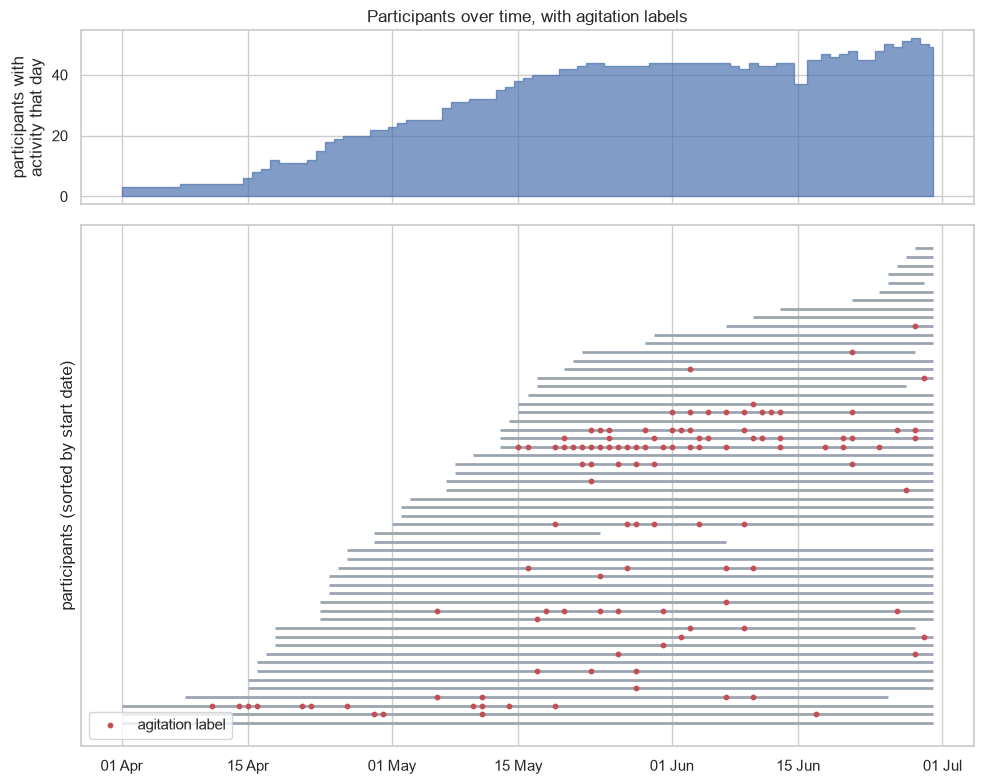

In [4]:
print("Participants per table:")
print({"Activity": A.patient_id.nunique(), "Physiology": P.patient_id.nunique(),
       "Sleep": S.patient_id.nunique(), "Labels": L.patient_id.nunique(), "Demographics": D.patient_id.nunique()})

# first day, last day and number of days with activity for each participant
span = A.groupby("patient_id").day.agg(first="min", last="max", active_days="nunique")
span["span_days"] = (span["last"] - span["first"]).dt.days + 1
span["days_without_activity"] = span.span_days - span.active_days
print("\nDays with activity per participant:")
print(span.active_days.describe().round(1).to_string())
print("\nParticipant-days with at least one activity event:", span.active_days.sum())
print("Participants with at least one empty day inside their own recording period:", (span.days_without_activity > 0).sum())

# timeline: when each participant was recorded, and when agitation labels were added
agit = L[L.type == "Agitation"].drop_duplicates(["patient_id", "day"])
order = span.sort_values("first")
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [1, 3]})
active_per_day = A.groupby("day").patient_id.nunique()
top.fill_between(active_per_day.index, active_per_day.values, step="mid", color="#4C72B0", alpha=.7)
top.set_ylabel("participants with\nactivity that day")
top.set_title("Participants over time, with agitation labels")
for i, (p, r) in enumerate(order.iterrows()):
    bottom.hlines(i, r["first"], r["last"], color="#9AA5B1", lw=2)
    d = agit[agit.patient_id == p].day
    bottom.scatter(d, [i] * len(d), s=10, color="#C44E52", zorder=3)
bottom.scatter([], [], s=10, color="#C44E52", label="agitation label")
bottom.legend(loc="lower left"); bottom.set_yticks([]); bottom.set_ylabel("participants (sorted by start date)")
bottom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
save("fig1_timeline")

*Note:* Participants did not all start together. The number recorded at the same time grows from a few in early April to about 45 in June, and recordings range from 3 to 89 days. Agitation labels (red) mostly appear in the later part of the study.

## 3. Activity sensors

location_name
Kitchen        227312
Hallway        193984
Lounge         180767
Bedroom        131133
Fridge Door    108803
Bathroom        82027
Front Door      58287
Back Door       48246


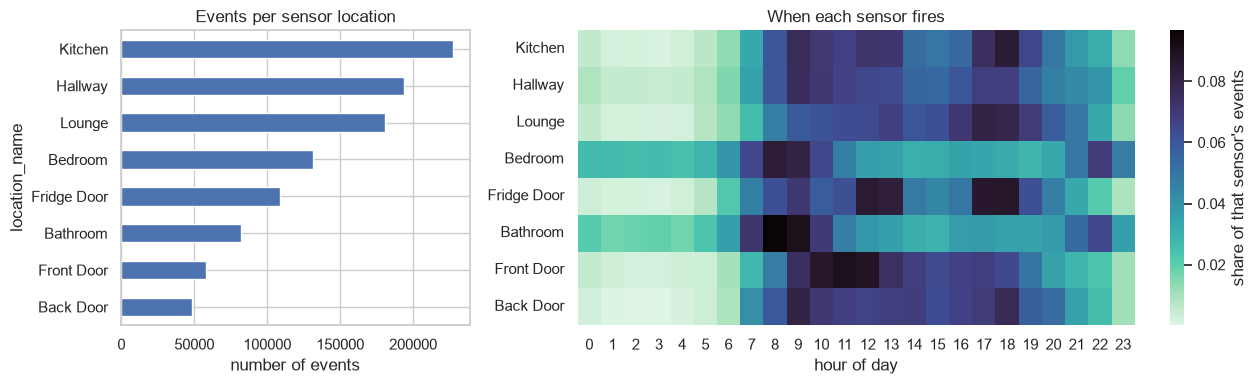


Events per active day, across participants:
count     56.0
mean     374.0
std      104.0
min      110.0
25%      315.0
50%      375.0
75%      420.0
max      711.0


In [5]:
loc_counts = A.location_name.value_counts()
print(loc_counts.to_string())

# share of each sensor's events that happen in each hour of the day
by_hour = pd.crosstab(A.location_name, A.date.dt.hour)
share = by_hour.div(by_hour.sum(axis=1), axis=0).loc[loc_counts.index]

fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2]})
loc_counts.sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Events per sensor location"); ax[0].set_xlabel("number of events")
sns.heatmap(share, cmap="mako_r", ax=ax[1], cbar_kws={"label": "share of that sensor's events"})
ax[1].set_title("When each sensor fires"); ax[1].set_xlabel("hour of day"); ax[1].set_ylabel("")
save("fig2_activity")

# how different are participants?
per_person = A.groupby("patient_id").size() / A.groupby("patient_id").day.nunique()
print("\nEvents per active day, across participants:")
print(per_person.describe().round(0).to_string())

*Note:* There are 8 sensor locations (the paper text mentions a dining room, but the data has none). Most sensors are quiet from midnight to about 5 am, but the bedroom and bathroom sensors stay noticeably active at night and peak at 8 to 9 am. The kitchen and fridge peak around mealtimes, and the front door in late morning. Participants differ a lot: from about 110 to 710 events per day.

## 4. Missing days

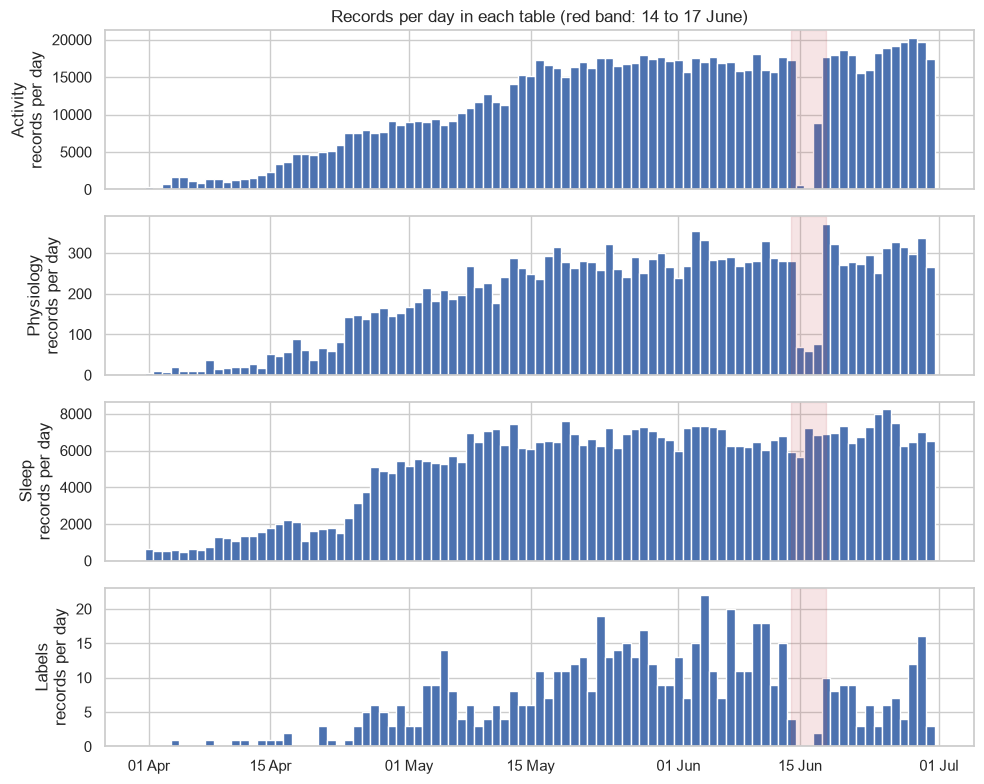

day
2019-06-13    17670
2019-06-14    17227
2019-06-15      544
2019-06-17     8906
2019-06-18    17738


In [6]:
all_days = pd.date_range("2019-04-01", "2019-06-30")
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, (name, df) in zip(axes, {"Activity": A, "Physiology": P, "Sleep": S, "Labels": L}.items()):
    per_day = df.groupby("day").size().reindex(all_days).fillna(0)
    ax.bar(per_day.index, per_day.values, width=1, color="#4C72B0")
    ax.axvspan(pd.Timestamp("2019-06-14"), pd.Timestamp("2019-06-18"), color="#C44E52", alpha=.15)
    ax.set_ylabel(name + "\nrecords per day")
axes[0].set_title("Records per day in each table (red band: 14 to 17 June)")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
save("fig3_missing_days")

daily = A.groupby("day").size()
print(daily["2019-06-13":"2019-06-18"].to_string())

*Note:* Activity almost disappears on 15 June (544 events) and is zero on 16 June, then is about half of normal on 17 June. Physiology drops too and no labels appear on those days, but sleep is unaffected. This fits the server failure described in the paper, although the paper gives 14 June and in our data 14 June looks normal.

## 5. Labels

,rows,participants,unique_participant_days
type,,,
Blood pressure,305,42,251
Agitation,135,27,115
Pulse,95,16,76
Body water,68,6,63
Weight,4,3,4
Body temperature,1,1,1


Agitation: 135 rows from 27 of 56 participants
Top participant (73f7c): 33 rows (24%); top 5 together: 59%
Agitation days: 114 of 2722 participant-days (4.2%)


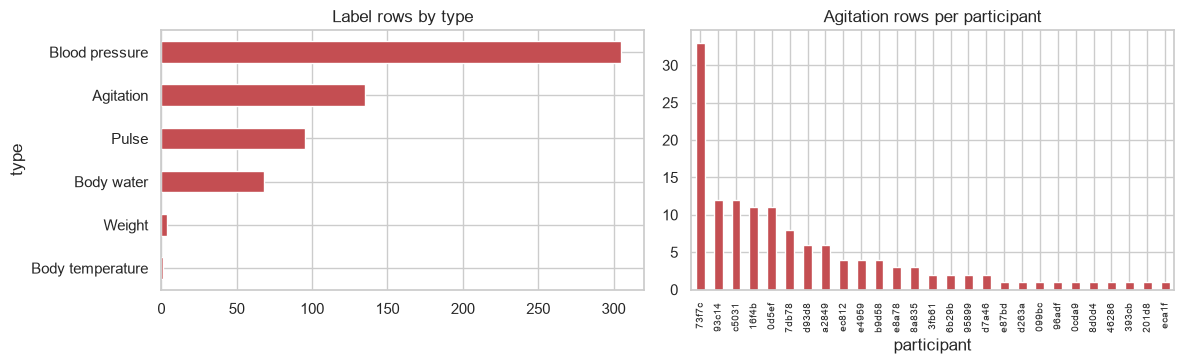

In [7]:
labels = L.groupby("type").agg(rows=("type", "size"), participants=("patient_id", "nunique"))
labels["unique_participant_days"] = L.drop_duplicates(["patient_id", "day", "type"]).groupby("type").size()
display(labels.sort_values("rows", ascending=False))

agit_rows = L[L.type == "Agitation"]
per_person_agit = agit_rows.groupby("patient_id").size().sort_values(ascending=False)
print(f"Agitation: {len(agit_rows)} rows from {len(per_person_agit)} of 56 participants")
print(f"Top participant ({per_person_agit.index[0]}): {per_person_agit.iloc[0]} rows ({per_person_agit.iloc[0]/len(agit_rows):.0%}); top 5 together: {per_person_agit.head(5).sum()/len(agit_rows):.0%}")

# how often is a participant-day an agitation day?
person_days = A.groupby(["patient_id", "day"]).size().reset_index()[["patient_id", "day"]]
agit_set = set(zip(agit_rows.patient_id, agit_rows.day))
person_days["agitation"] = [(p, d) in agit_set for p, d in zip(person_days.patient_id, person_days.day)]
print(f"Agitation days: {person_days.agitation.sum()} of {len(person_days)} participant-days ({person_days.agitation.mean():.1%})")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
labels.rows.sort_values().plot.barh(ax=ax[0], color="#C44E52"); ax[0].set_title("Label rows by type")
per_person_agit.plot.bar(ax=ax[1], color="#C44E52"); ax[1].set_title("Agitation rows per participant")
ax[1].tick_params(axis="x", labelsize=7); ax[1].set_xlabel("participant")
save("fig4_labels")

*Note:* Blood pressure (305) and agitation (135) dominate; weight has 4 rows and body temperature just 1, which is too few to study. Agitation labels are spread very unevenly. One participant has a quarter of them and 29 participants have none. Only about 4% of participant-days are agitation days.

### Label timestamps

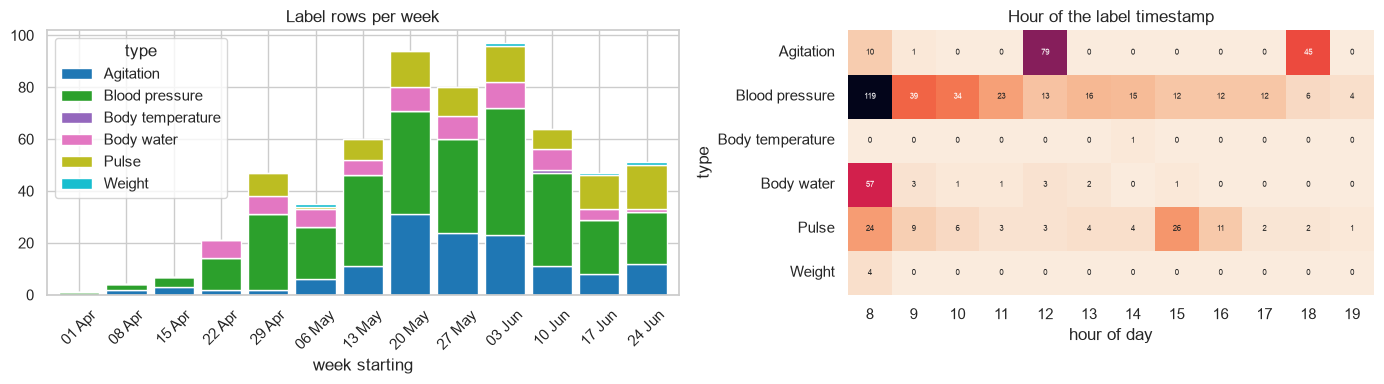

In [8]:
L["hour"] = L.date.dt.hour
by_type_hour = pd.crosstab(L.type, L.hour)

weekly = L.groupby([L.date.dt.to_period("W").dt.start_time, "type"]).size().unstack(fill_value=0)
weekly.index = [d.strftime("%d %b") for d in weekly.index]

fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.2, 1]})
weekly.plot.bar(stacked=True, ax=ax[0], width=.85, colormap="tab10")
ax[0].set_title("Label rows per week"); ax[0].set_xlabel("week starting"); ax[0].tick_params(axis="x", rotation=45)
sns.heatmap(by_type_hour, cmap="rocket_r", annot=True, fmt="d", annot_kws={"size": 6}, cbar=False, ax=ax[1])
ax[1].set_title("Hour of the label timestamp"); ax[1].set_xlabel("hour of day")
save("fig5_label_timing")

*Note:* Labels per week climb from almost none in April to about 30 a week in late May. The time of day is also very regular for each type: agitation labels are almost all stamped around 12:00 or 18:00, blood pressure in the morning. So the timestamp is probably when the label was recorded, not when the event happened (our guess, not tested).

## 6. Sleep and physiology

In [9]:
# Sleep: which night does each minute belong to (start counting nights at noon)
S["night"] = (S.date - pd.Timedelta(hours=12)).dt.normalize()
nights = S.groupby("patient_id").night.nunique()
print("Participants with sleep data:", len(nights))
print("Nights per participant:", nights.describe().round(0).to_dict())
print("Share of minutes by sleep state:", S.state.value_counts(normalize=True).round(3).to_dict())
print("Snoring share of minutes:", round(S.snoring.mean(), 3))
display(S.groupby("state")[["heart_rate", "respiratory_rate"]].mean().round(1))

Participants with sleep data: 17
Nights per participant: {'count': 17.0, 'mean': 48.0, 'std': 25.0, 'min': 4.0, '25%': 30.0, '50%': 55.0, '75%': 66.0, 'max': 83.0}
Share of minutes by sleep state: {'LIGHT': 0.518, 'AWAKE': 0.203, 'DEEP': 0.194, 'REM': 0.085}
Snoring share of minutes: 0.035


,heart_rate,respiratory_rate
state,,
AWAKE,65.6,15.9
DEEP,58.5,14.9
LIGHT,59.8,14.8
REM,61.6,15.3


In [10]:
# Physiology: how many readings, from how many people, on how many days
person_days_set = set(zip(person_days.patient_id, person_days.day))
rows = []
for dev, g in P.groupby("device_type"):
    have = set(zip(g.patient_id, g.day))
    covered = np.mean([k in have for k in person_days_set])
    rows.append({"device": dev, "readings": len(g), "participants": g.patient_id.nunique(),
                 "share of participant-days with a reading": round(covered, 2),
                 "min": g.value.min(), "max": g.value.max()})
display(pd.DataFrame(rows).set_index("device").sort_values("readings", ascending=False))

# values outside a broad "plausible" range that we chose ourselves
limits = {"Body Temperature": (34, 40), "Skin Temperature": (25, 40),
          "Systolic blood pressure": (70, 180), "Diastolic blood pressure": (40, 120)}
out = []
for dev, (lo, hi) in limits.items():
    g = P[P.device_type == dev]
    bad = g[(g.value < lo) | (g.value > hi)]
    out.append({"device": dev, "our range": f"{lo} to {hi}", "readings outside": len(bad),
                "most extreme": bad.value.max() if len(bad) else None})
display(pd.DataFrame(out).set_index("device"))

,readings,participants,share of participant-days with a reading,min,max
device,,,,,
Body Temperature,5617,55,0.74,32.147,42.960
Diastolic blood pressure,2305,54,0.63,40.000,194.000
Heart rate,2305,54,0.63,42.000,132.000
Systolic blood pressure,2305,54,0.63,70.000,211.000
Body weight,1874,46,0.52,44.400,101.700
O/E - muscle mass,1264,45,0.41,30.300,70.500
Total body water,1264,45,0.41,36.000,78.000
Skin Temperature,745,13,0.21,29.082,74.127


,our range,readings outside,most extreme
device,,,
Body Temperature,34 to 40,5,42.960
Skin Temperature,25 to 40,2,74.127
Systolic blood pressure,70 to 180,30,211.000
Diastolic blood pressure,40 to 120,17,194.000


*Note:* Only 17 participants have sleep data, with between 4 and 83 nights each. Heart rate is lowest in deep sleep (about 58 bpm) and highest when awake (about 66). Physiology is sparse: body temperature is available on about 74% of participant-days but skin temperature on only 21% (and for just 13 participants). There are a few impossible values, such as a skin temperature of 74 °C. High blood pressure readings are real clinical signals and should not be thrown away as outliers.

## 7. A first look: do agitation days look different?

Participants used: 12


,median,share_higher,wilcoxon_p
feature,,,
bathroom events,0.585,0.917,0.016
front door events,0.460,0.667,0.151
share of events at night,-0.397,0.167,0.034
total events,0.960,1.000,0.000


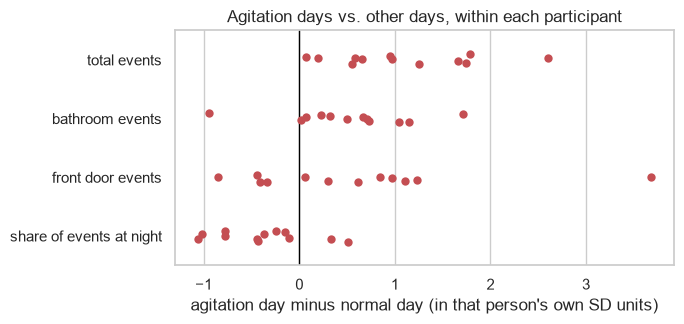

In [11]:
# build simple daily features from the activity log
daily = A.groupby(["patient_id", "day"]).agg(
    events=("date", "size"),
    night_events=("date", lambda s: ((s.dt.hour < 6) | (s.dt.hour >= 22)).sum()),
    bathroom=("location_name", lambda s: (s == "Bathroom").sum()),
    front_door=("location_name", lambda s: (s == "Front Door").sum()),
).reset_index()
daily["night_share"] = daily.night_events / daily.events
daily["agitation"] = [(p, d) in agit_set for p, d in zip(daily.patient_id, daily.day)]

# leave out the server-failure days and days with very few events
bad_days = pd.to_datetime(["2019-06-15", "2019-06-16", "2019-06-17"])
daily = daily[(daily.events >= 100) & (~daily.day.isin(bad_days))]

# only use participants with enough agitation days and enough other days
counts = daily.groupby("patient_id").agitation.agg(["sum", "size"])
keep = counts[(counts["sum"] >= 3) & (counts["size"] - counts["sum"] >= 10)].index
print("Participants used:", len(keep))

# for each participant: how much higher/lower is an agitation day than their normal day?
# (difference divided by that person's own day-to-day spread)
features = {"events": "total events", "bathroom": "bathroom events", "front_door": "front door events", "night_share": "share of events at night"}
results = []
for p in keep:
    g = daily[daily.patient_id == p]
    for col, nice in features.items():
        diff = g[g.agitation][col].mean() - g[~g.agitation][col].mean()
        results.append({"participant": p, "feature": nice, "z": diff / g[~g.agitation][col].std()})
results = pd.DataFrame(results)

summary = results.groupby("feature").z.agg(median="median", share_higher=lambda z: (z > 0).mean())
summary["wilcoxon_p"] = [stats.wilcoxon(results[results.feature == f].z).pvalue for f in summary.index]
display(summary.round(3))

fig, ax = plt.subplots(figsize=(7, 3.4))
sns.stripplot(data=results, x="z", y="feature", color="#C44E52", size=6, ax=ax)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("agitation day minus normal day (in that person's own SD units)"); ax.set_ylabel("")
ax.set_title("Agitation days vs. other days, within each participant")
save("fig6_agitation_days")

*Note:* In all 12 participants who could be included, total activity is higher on agitation-labelled days, and bathroom activity is higher in 11 of 12. The night share is lower in most, mainly because the daytime total is higher. This is only a rough descriptive check (12 people, several tests, household-level sensors, and the labels were partly produced from activity data), so we do not treat it as a result about predicting agitation.

## Issues found (summary)
Details and discussion are in the report.
- Server failure: activity almost missing on 15 to 17 June 2019.
- Missing data is hidden in absent rows (sleep: 17 of 56 participants; physiology only on some days).
- Labels are positives only, timestamps look like record times, and label counts grow over time.
- Labels are concentrated in a few participants, and some types have almost no rows.
- Activity is household level, and participants differ a lot in how much activity they produce.
- A few physiology values are impossible (e.g. skin temperature of 74 °C).